In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import time

# --------------------------------------------------
# CONFIGURATION DU PROJET
# --------------------------------------------------

CURRENT_DIR = Path.cwd().resolve()
SEARCH_ROOTS = [CURRENT_DIR, *CURRENT_DIR.parents]
EXCEL_FILE = next(
    (
        candidate
        for root in SEARCH_ROOTS
        for candidate in (root / "Classeur3.xlsx", root / "data" / "Classeur3.xlsx")
        if candidate.is_file()
    ),
    None,
)

if EXCEL_FILE is None:
    raise FileNotFoundError(
        "Classeur3.xlsx est introuvable. Placez-le à la racine du projet "
        "ou dans son sous-dossier data/. "
        f"Dossier courant : {CURRENT_DIR}"
    )

BASE_DIR = EXCEL_FILE.parent.parent if EXCEL_FILE.parent.name == "data" else EXCEL_FILE.parent
OUTPUT_DIR = BASE_DIR / "outputs"

# Groupes ATC étudiés
atc_cols = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

expected_sheets = [
    "Pharma_Ventes_Daily",
    "Pharma_Ventes_Hourly",
    "Pharma_Ventes_Weekly",
    "Pharma_Ventes_Monthly",
]
expected_columns = {"datum", *atc_cols}

# Localisation météo par défaut
DEFAULT_LOCATION = "Montpellier"

# Style des graphiques
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
plt.rcParams["figure.figsize"] = (12, 6)

# --------------------------------------------------
# CHARGEMENT ET VALIDATION DES DONNÉES
# --------------------------------------------------

print("Dossier du projet :", BASE_DIR)
print("Fichier source utilisé :", EXCEL_FILE.resolve())
print("Fichier présent :", EXCEL_FILE.is_file())

try:
    workbook = pd.ExcelFile(EXCEL_FILE)
except Exception as error:
    raise ValueError(
        f"Impossible de lire le classeur Excel {EXCEL_FILE}. "
        "Vérifiez qu'il s'agit d'un fichier .xlsx valide et qu'il n'est pas endommagé."
    ) from error

missing_sheets = [sheet for sheet in expected_sheets if sheet not in workbook.sheet_names]
if missing_sheets:
    raise ValueError(
        f"Feuilles manquantes dans {EXCEL_FILE.name} : {missing_sheets}. "
        f"Feuilles disponibles : {workbook.sheet_names}"
    )

frames = {sheet: pd.read_excel(workbook, sheet_name=sheet) for sheet in expected_sheets}
missing_columns = {
    sheet: sorted(expected_columns - set(frame.columns))
    for sheet, frame in frames.items()
    if expected_columns - set(frame.columns)
}
if missing_columns:
    details = "; ".join(
        f"{sheet}: {columns}" for sheet, columns in missing_columns.items()
    )
    raise ValueError(f"Colonnes attendues manquantes : {details}")

df_daily = frames["Pharma_Ventes_Daily"]
df_hourly = frames["Pharma_Ventes_Hourly"]
df_weekly = frames["Pharma_Ventes_Weekly"]
df_monthly = frames["Pharma_Ventes_Monthly"]

print("Feuilles attendues et colonnes requises vérifiées.")
for sheet, frame in frames.items():
    print(f"{sheet}: {len(frame):,} lignes x {len(frame.columns)} colonnes")


/Users/manondesclaux/Desktop/EPITECH/RUSH 2/Rush2_Pharma/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Dossier du projet : /Users/manondesclaux/Desktop/EPITECH/RUSH 2/Rush2_Pharma
Fichier source utilisé : /Users/manondesclaux/Desktop/EPITECH/RUSH 2/Rush2_Pharma/Classeur3.xlsx
Fichier présent : True
Feuilles attendues et colonnes requises vérifiées.
Pharma_Ventes_Daily: 2,106 lignes x 13 colonnes
Pharma_Ventes_Hourly: 50,532 lignes x 13 colonnes
Pharma_Ventes_Weekly: 302 lignes x 9 colonnes
Pharma_Ventes_Monthly: 70 lignes x 9 colonnes


In [2]:
# Conversion des dates et des ventes, sans imputation automatique

df_daily_raw = df_daily.copy(deep=True)
df_daily["datum_dt"] = pd.to_datetime(df_daily["datum"], errors="coerce")
df_daily = df_daily.sort_values("datum_dt", na_position="last").reset_index(drop=True)

invalid_date_mask = df_daily["datum"].notna() & df_daily["datum_dt"].isna()
duplicate_date_mask = (
    df_daily["datum_dt"].notna()
    & df_daily["datum_dt"].duplicated(keep=False)
)
quality_records = []
for column in atc_cols:
    raw_values = df_daily_raw[column]
    numeric_values = pd.to_numeric(raw_values, errors="coerce")
    invalid_numeric = raw_values.notna() & numeric_values.isna()
    negative_values = numeric_values.notna() & numeric_values.lt(0)
    df_daily[column] = numeric_values
    quality_records.append(
        {
            "Code ATC": column,
            "Valeurs manquantes source": int(raw_values.isna().sum()),
            "Valeurs non numériques": int(invalid_numeric.sum()),
            "Valeurs négatives": int(negative_values.sum()),
            "Zéros explicites": int(numeric_values.eq(0).sum()),
            "Valeurs conservées": int(numeric_values.notna().sum()),
        }
    )

quality_audit = pd.DataFrame(quality_records)
print("=== CONTROLES QUALITE DES VENTES JOURNALIERES ===")
print(
    "Dates invalides :", int(invalid_date_mask.sum()),
    "| dates dupliquees :", int(duplicate_date_mask.sum()),
    "| ventes manquantes ou invalides conservees comme NaN."
)
print(quality_audit.to_string(index=False))
print("=== STATISTIQUES DESCRIPTIVES (VENTES JOURNALIERES) ===")
print(df_daily[atc_cols].describe().round(2))

=== CONTROLES QUALITE DES VENTES JOURNALIERES ===
Dates invalides : 0 | dates dupliquees : 0 | ventes manquantes ou invalides conservees comme NaN.
Code ATC  Valeurs manquantes source  Valeurs non numériques  Valeurs négatives  Zéros explicites  Valeurs conservées
   M01AB                          0                       0                  0                14                2106
   M01AE                          0                       0                  0                10                2106
   N02BA                          0                       0                  0                54                2106
   N02BE                          0                       0                  0                 0                2106
    N05B                         37                       0                  0                18                2069
    N05C                          0                       0                  0              1437                2106
     R03                         

In [3]:
# Jours feries officiels : API publique de l'Etat
url_feries = "https://calendrier.api.gouv.fr/jours-feries/metropole.json"
df_daily["is_holiday"] = pd.Series(pd.NA, index=df_daily.index, dtype="Int64")
df_daily["holiday_name"] = pd.NA

try:
    response = requests.get(url_feries, timeout=20)
    response.raise_for_status()
    feries_dict = response.json()
    holiday_dates = pd.to_datetime(list(feries_dict.keys()), errors="coerce").normalize()
    holiday_map = dict(zip(holiday_dates, feries_dict.values()))
    sales_dates = df_daily["datum_dt"].dt.normalize()
    holiday_names = sales_dates.map(holiday_map)
    covered_dates = (
        sales_dates.notna()
        & sales_dates.ge(holiday_dates.min())
        & sales_dates.le(holiday_dates.max())
    )
    df_daily["holiday_name"] = holiday_names
    df_daily.loc[covered_dates, "is_holiday"] = (
        holiday_names.loc[covered_dates].notna().astype("int64")
    )
    print(
        f"Jours feries recupes : {len(holiday_dates)} dates, "
        f"du {holiday_dates.min().date()} au {holiday_dates.max().date()}."
    )
    if df_daily["datum_dt"].notna().any():
        sales_start = df_daily["datum_dt"].min().normalize()
        sales_end = df_daily["datum_dt"].max().normalize()
        print(
            "Couverture des ventes :",
            sales_start >= holiday_dates.min() and sales_end <= holiday_dates.max(),
            f"({sales_start.date()} au {sales_end.date()})",
        )
except (requests.RequestException, ValueError, KeyError) as error:
    print(f"Jours feries indisponibles ({error}). Statut conserve comme inconnu.")

# Variables de calendrier independantes de la disponibilité de l'API
df_daily["month"] = df_daily["datum_dt"].dt.month
df_daily["dayofweek"] = df_daily["datum_dt"].dt.dayofweek
df_daily["is_weekend"] = df_daily["dayofweek"].isin([5, 6]).astype("int64")

Jours feries recupes : 285 dates, du 2006-01-01 au 2031-12-25.
Couverture des ventes : True (2014-01-02 au 2019-10-08)


In [4]:
# Comparaisons descriptives selon le calendrier
saisonnalite = df_daily.groupby("month")[atc_cols].mean()
weekday_names = {
    0: "Lundi", 1: "Mardi", 2: "Mercredi", 3: "Jeudi",
    4: "Vendredi", 5: "Samedi", 6: "Dimanche",
}
weekday_summary = df_daily.groupby("dayofweek")[atc_cols].mean().rename(index=weekday_names)
calendar_comparisons = []
monthly_residuals = {
    column: df_daily[column] - df_daily.groupby("month")[column].transform("mean")
    for column in atc_cols
}

for label, column in (
    ("Jour de semaine", "dayofweek"),
    ("Semaine / week-end", "is_weekend"),
    ("Jour ferie", "is_holiday"),
):
    for value, group in df_daily.groupby(column, dropna=False):
        if column == "dayofweek":
            group_name = weekday_names.get(value, str(value))
        elif column == "is_weekend":
            group_name = "Week-end" if value == 1 else "Semaine"
        else:
            group_name = "Ferie" if value == 1 else "Non ferie" if value == 0 else "Inconnu"
        row = {"Comparaison": label, "Groupe": group_name, "Jours observes": len(group)}
        row.update(group[atc_cols].mean().to_dict())
        row.update(
            {
                f"{atc} centre par mois": monthly_residuals[atc].loc[group.index].mean()
                for atc in atc_cols
            }
        )
        calendar_comparisons.append(row)

calendar_comparisons = pd.DataFrame(calendar_comparisons)
print("=== MOYENNES JOURNALIERES PAR MOIS ===")
print(saisonnalite.round(2))
print("=== MOYENNES PAR JOUR, WEEK-END ET JOUR FERIE ===")
print(calendar_comparisons.round(2).to_string(index=False))
print("Les colonnes 'centre par mois' reduisent les ecarts de saisonnalite; elles restent descriptives.")

=== MOYENNES JOURNALIERES PAR MOIS ===
       M01AB  M01AE  N02BA  N02BE   N05B  N05C   R03   R06
month                                                     
1       5.32   4.67   4.49  44.15  10.21  0.75  7.16  1.60
2       4.95   4.66   4.71  36.37   8.90  0.54  6.85  1.68
3       4.91   3.89   3.99  29.93   8.28  0.62  6.29  3.18
4       5.25   3.72   3.77  26.83   7.90  0.48  5.87  4.91
5       4.88   3.72   3.74  23.23   7.53  0.61  4.97  5.05
6       4.71   3.57   3.75  20.63   7.89  0.59  4.35  4.44
7       5.21   3.77   3.48  19.53   8.29  0.48  2.96  3.36
8       5.43   3.62   3.48  20.57   9.13  0.61  3.10  2.69
9       5.00   3.97   3.37  32.03   9.26  0.52  4.42  2.57
10      4.98   3.92   3.98  42.15   9.18  0.52  7.22  1.96
11      5.23   3.81   4.19  32.56   9.27  0.67  6.23  1.57
12      5.26   4.20   3.81  41.45   9.89  0.73  8.37  1.46
=== MOYENNES PAR JOUR, WEEK-END ET JOUR FERIE ===
       Comparaison    Groupe  Jours observes  M01AB  M01AE  N02BA  N02BE  N05B  N05C 

### Localisation de référence

La ville saisie dans la cellule météo suivante sert à la météo et à l'indicateur grippal. Montpellier est proposé par défaut. La région Sentinelles est déduite automatiquement du département de la ville ; les régions Sentinelles utilisent un ancien découpage administratif. Pour une autre pharmacie, saisissez sa commune dans cette cellule.

In [ ]:
# Meteo historique quotidienne (reanalysee ERA5, pas une mesure locale)
weather_city = input(
    f"Ville de la pharmacie pour la meteo [{DEFAULT_LOCATION}] : "
).strip() or DEFAULT_LOCATION
weather_source = "Open-Meteo Historical Weather API"
weather_model = "ERA5 reanalysis"
weather_columns = [
    "temperature_mean_c", "temperature_min_c",
    "temperature_max_c", "precipitation_mm",
]
weather_metadata = {
    "city_requested": weather_city,
    "source": weather_source,
    "model": weather_model,
    "latitude": pd.NA,
    "longitude": pd.NA,
    "timezone": "Europe/Paris",
    "status": "indisponible",
}
df_weather = pd.DataFrame(columns=["datum_dt", *weather_columns])

try:
    geocode_response = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={"name": weather_city, "count": 10, "language": "fr", "format": "json", "countryCode": "FR"},
        timeout=20,
    )
    geocode_response.raise_for_status()
    locations = geocode_response.json().get("results", [])
    if not locations:
        raise ValueError(f"Ville introuvable en France : {weather_city}")
    location = locations[0]
    weather_metadata.update(
        {
            "city_resolved": location.get("name"),
            "admin1": location.get("admin1"),
            "latitude": location["latitude"],
            "longitude": location["longitude"],
            "timezone": location.get("timezone", "Europe/Paris"),
        }
    )

    sales_start = df_daily["datum_dt"].min().date()
    sales_end = df_daily["datum_dt"].max().date()
    weather_response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": location["latitude"],
            "longitude": location["longitude"],
            "start_date": sales_start.isoformat(),
            "end_date": sales_end.isoformat(),
            "daily": "temperature_2m_mean,temperature_2m_min,temperature_2m_max,precipitation_sum",
            "timezone": weather_metadata["timezone"],
            "models": "era5",
        },
        timeout=60,
    )
    weather_response.raise_for_status()
    weather_payload = weather_response.json()
    if "daily" not in weather_payload:
        raise ValueError(weather_payload.get("reason", "Réponse météo sans données quotidiennes"))
    df_weather = pd.DataFrame(weather_payload["daily"]).rename(
        columns={
            "time": "datum_dt",
            "temperature_2m_mean": "temperature_mean_c",
            "temperature_2m_min": "temperature_min_c",
            "temperature_2m_max": "temperature_max_c",
            "precipitation_sum": "precipitation_mm",
        }
    )
    df_weather["datum_dt"] = pd.to_datetime(df_weather["datum_dt"], errors="coerce")
    missing_weather_columns = set(weather_columns) - set(df_weather.columns)
    if missing_weather_columns:
        raise ValueError(f"Variables météo absentes : {sorted(missing_weather_columns)}")
    weather_metadata.update(
        {
            "latitude_grid": weather_payload.get("latitude"),
            "longitude_grid": weather_payload.get("longitude"),
            "elevation_m": weather_payload.get("elevation"),
            "status": "ok",
            "date_debut": df_weather["datum_dt"].min().date(),
            "date_fin": df_weather["datum_dt"].max().date(),
        }
    )
    expected_start = pd.Timestamp(sales_start)
    expected_end = pd.Timestamp(sales_end)
    covered = (
        df_weather["datum_dt"].min() <= expected_start
        and df_weather["datum_dt"].max() >= expected_end
    )
    print(
        f"Météo récupérée pour {location.get('name')} ({location.get('admin1', '')}) : "
        f"{len(df_weather)} jours, couverture complète={covered}."
    )
    print(
        f"Coordonnées demandées : {location['latitude']}, {location['longitude']} ; "
        f"source : {weather_source}, modèle : {weather_model}."
    )
except (requests.RequestException, ValueError, KeyError, IndexError) as error:
    weather_metadata["error"] = str(error)
    print(
        f"Météo indisponible ({error}). Les colonnes météo resteront manquantes; "
        "aucune valeur ne sera imputée."
    )

existing_weather_columns = [column for column in weather_columns if column in df_daily.columns]
df_daily = df_daily.drop(columns=existing_weather_columns).merge(
    df_weather, on="datum_dt", how="left", validate="one_to_one"
)
weather_metadata = pd.DataFrame([weather_metadata])
print("Jours sans météo fusionnée :", int(df_daily[weather_columns[0]].isna().sum()))

In [ ]:
# Correlations descriptives meteo-ventes, brutes et apres retrait des moyennes mensuelles
weather_analysis_rows = []
for atc in atc_cols:
    sales_by_month = df_daily.groupby("month")[atc].transform("mean")
    sales_deseasonalized = df_daily[atc] - sales_by_month
    for weather_column in weather_columns:
        weather_values = pd.to_numeric(df_daily[weather_column], errors="coerce")
        valid = df_daily[atc].notna() & weather_values.notna()
        observations = int(valid.sum())
        if observations < 3:
            continue
        weather_by_month = weather_values.groupby(df_daily["month"]).transform("mean")
        weather_deseasonalized = weather_values - weather_by_month
        adjusted_valid = valid & sales_deseasonalized.notna() & weather_deseasonalized.notna()
        weather_analysis_rows.append(
            {
                "Code ATC": atc,
                "Variable meteo": weather_column,
                "Jours compares": observations,
                "Correlation brute": df_daily.loc[valid, atc].corr(weather_values.loc[valid]),
                "Correlation apres centrage mensuel": sales_deseasonalized.loc[
                    adjusted_valid
                ].corr(weather_deseasonalized.loc[adjusted_valid]),
            }
        )

weather_correlations = pd.DataFrame(weather_analysis_rows)
if not weather_correlations.empty:
    print(weather_correlations.round(3).to_string(index=False))
    adjusted_matrix = weather_correlations.pivot(
        index="Code ATC",
        columns="Variable meteo",
        values="Correlation apres centrage mensuel",
    ).reindex(index=atc_cols, columns=weather_columns)
    fig, ax = plt.subplots(figsize=(10, 5))
    image = ax.imshow(adjusted_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(weather_columns)), labels=weather_columns, rotation=20, ha="right")
    ax.set_yticks(range(len(atc_cols)), labels=atc_cols)
    ax.set_title("Corrélations météo-ventes après centrage par mois")
    for row_index in range(len(atc_cols)):
        for column_index in range(len(weather_columns)):
            value = adjusted_matrix.iloc[row_index, column_index]
            if pd.notna(value):
                ax.text(column_index, row_index, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image, ax=ax, label="Corrélation de Pearson")
    fig.tight_layout()
    plt.show()
else:
    print("Analyse météo impossible : aucune mesure météo disponible.")

print(
    "Ces corrélations sont exploratoires, non causales; le centrage mensuel "
    "ne corrige ni les tendances, ni l'autocorrélation, ni les facteurs confondants."
)

In [ ]:
# Indicateur hebdomadaire Sentinelles sélectionné depuis la ville de référence
import io
import unicodedata

health_source_url = "https://www.sentiweb.fr/datasets/incidence-REG-3.csv"
health_source_name = "Réseau Sentinelles, indicateur 3 (syndromes grippaux)"
health_required_columns = {
    "week", "indicator", "inc", "inc_low", "inc_up",
    "inc100", "inc100_low", "inc100_up", "geo_insee", "geo_name",
}
df_health = pd.DataFrame(
    columns=["week_id", "week_start", "inc100", "inc100_low", "inc100_up"]
)
health_correlations = pd.DataFrame()
health_metadata = {
    "source": health_source_name,
    "url": health_source_url,
    "frequency": "hebdomadaire",
    "reference_city": weather_city,
    "status": "indisponible",
}

# Codes départementaux rattachés aux anciennes régions publiées par Sentinelles.
legacy_regions = {
    "42": ("ALSACE", {"67", "68"}),
    "72": ("AQUITAINE", {"24", "33", "40", "47", "64"}),
    "83": ("AUVERGNE", {"03", "15", "43", "63"}),
    "25": ("BASSE-NORMANDIE", {"14", "50", "61"}),
    "26": ("BOURGOGNE", {"21", "58", "71", "89"}),
    "53": ("BRETAGNE", {"22", "29", "35", "56"}),
    "24": ("CENTRE", {"18", "28", "36", "37", "41", "45"}),
    "21": ("CHAMPAGNE-ARDENNE", {"08", "10", "51", "52"}),
    "94": ("CORSE", {"2A", "2B"}),
    "43": ("FRANCHE-COMTE", {"25", "39", "70", "90"}),
    "23": ("HAUTE-NORMANDIE", {"27", "76"}),
    "91": ("LANGUEDOC-ROUSSILLON", {"11", "30", "34", "48", "66"}),
    "74": ("LIMOUSIN", {"19", "23", "87"}),
    "41": ("LORRAINE", {"54", "55", "57", "88"}),
    "73": ("MIDI-PYRENEES", {"09", "12", "31", "32", "46", "65", "81", "82"}),
    "31": ("NORD-PAS-DE-CALAIS", {"59", "62"}),
    "52": ("PAYS-DE-LA-LOIRE", {"44", "49", "53", "72", "85"}),
    "22": ("PICARDIE", {"02", "60", "80"}),
    "54": ("POITOU-CHARENTES", {"16", "17", "79", "86"}),
    "93": ("PROVENCE-ALPES-COTE-D-AZUR", {"04", "05", "06", "13", "83", "84"}),
    "11": ("ILE-DE-FRANCE", {"75", "77", "78", "91", "92", "93", "94", "95"}),
    "82": ("RHONE-ALPES", {"01", "07", "26", "38", "42", "69", "73", "74"}),
    "0": ("OUTRE-MER", {"971", "972", "973", "974", "976"}),
}
department_to_sentinelles = {
    department_code: (region_code, region_name)
    for region_code, (region_name, department_codes) in legacy_regions.items()
    for department_code in department_codes
}

def normalize_location_name(value):
    normalized = unicodedata.normalize("NFKD", str(value))
    return "".join(character for character in normalized if not unicodedata.combining(character)).casefold().strip()

try:
    health_response = requests.get(health_source_url, timeout=30)
    health_response.raise_for_status()
    health_source = pd.read_csv(
        io.BytesIO(health_response.content), comment="#", encoding="ISO-8859-1"
    )
    missing_health_columns = health_required_columns - set(health_source.columns)
    if missing_health_columns:
        raise ValueError(f"Colonnes absentes de la source : {sorted(missing_health_columns)}")

    health_source["week_id"] = pd.to_numeric(
        health_source["week"], errors="coerce"
    ).astype("Int64")
    health_source["indicator"] = pd.to_numeric(
        health_source["indicator"], errors="coerce"
    )
    for column in ("inc100", "inc100_low", "inc100_up"):
        health_source[column] = pd.to_numeric(health_source[column], errors="coerce")

    health_geocode_response = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={
            "name": weather_city,
            "count": 10,
            "language": "fr",
            "format": "json",
            "countryCode": "FR",
        },
        timeout=20,
    )
    health_geocode_response.raise_for_status()
    locations = health_geocode_response.json().get("results", [])
    exact_locations = [
        place for place in locations
        if normalize_location_name(place.get("name", ""))
        == normalize_location_name(weather_city)
    ]
    if not exact_locations:
        raise ValueError(f"Ville française introuvable ou ambiguë : {weather_city}")
    location = exact_locations[0]
    department_name = location.get("admin2")
    if not department_name:
        raise ValueError(f"Département introuvable pour {location.get('name')}.")

    departments_response = requests.get(
        "https://geo.api.gouv.fr/departements",
        params={"fields": "code,nom", "format": "json"},
        timeout=20,
    )
    departments_response.raise_for_status()
    matching_departments = [
        department for department in departments_response.json()
        if normalize_location_name(department.get("nom", ""))
        == normalize_location_name(department_name)
    ]
    if len(matching_departments) != 1:
        raise ValueError(
            f"Correspondance officielle impossible pour le département {department_name}."
        )
    department_code = matching_departments[0]["code"]
    if department_code not in department_to_sentinelles:
        raise ValueError(
            f"Aucune ancienne région Sentinelles n'est définie pour le département {department_code}."
        )
    sentinelles_code, sentinelles_name = department_to_sentinelles[department_code]

    health_regions = (
        health_source[["geo_insee", "geo_name"]]
        .drop_duplicates()
        .sort_values("geo_name")
        .reset_index(drop=True)
    )
    print(
        f"Ville de référence : {location['name']} ({location.get('admin1')}, "
        f"département {department_name}, code {department_code})."
    )
    print(
        f"Région historique Sentinelles sélectionnée automatiquement : "
        f"{sentinelles_name} (code {sentinelles_code})."
    )
    print("Source hebdomadaire Sentinelles, indicateur 3. Colonnes :", sorted(health_source.columns))
    print(
        "Période source (année-semaine ISO) :",
        int(health_source["week_id"].min()), "à", int(health_source["week_id"].max()),
    )
    print(
        "La source change de définition à partir de 2020-S12; "
        "les comparaisons avant/après doivent être interprétées avec prudence."
    )

    region_mask = (
        health_source["geo_insee"].astype(str).str.strip().eq(sentinelles_code)
        & health_source["indicator"].eq(3)
    )
    selected_health = health_source.loc[region_mask].copy()
    matched_regions = selected_health[["geo_insee", "geo_name"]].drop_duplicates()
    if len(matched_regions) != 1:
        raise ValueError(
            f"La région Sentinelles {sentinelles_name} (code {sentinelles_code}) "
            "n'est pas présente de manière unique dans le fichier téléchargé."
        )
    selected_health["week_id"] = selected_health["week_id"].astype("int64")
    selected_health["week_start"] = selected_health["week_id"].map(
        lambda value: pd.Timestamp.fromisocalendar(value // 100, value % 100, 1)
    )
    if selected_health["week_id"].duplicated().any():
        raise ValueError("Plusieurs valeurs existent pour une semaine et un territoire.")
    df_health = selected_health[
        ["week_id", "week_start", "inc100", "inc100_low", "inc100_up"]
    ].sort_values("week_id")

    daily_for_weeks = df_daily.assign(
        week_start=df_daily["datum_dt"].dt.to_period("W-SUN").dt.start_time
    )
    iso_weeks = daily_for_weeks["week_start"].dt.isocalendar()
    daily_for_weeks["week_id"] = (
        iso_weeks.year.astype("int64") * 100
        + iso_weeks.week.astype("int64")
    )
    week_day_counts = daily_for_weeks.groupby("week_id")["datum_dt"].nunique()
    complete_week_ids = week_day_counts[week_day_counts.eq(7)].index
    weekly_sales = (
        daily_for_weeks.loc[daily_for_weeks["week_id"].isin(complete_week_ids)]
        .groupby("week_id")[atc_cols]
        .sum(min_count=7)
        .reset_index()
    )
    weekly_sales["week_start"] = weekly_sales["week_id"].map(
        lambda value: pd.Timestamp.fromisocalendar(value // 100, value % 100, 1)
    )
    health_sales_comparison = weekly_sales.merge(
        df_health, on=["week_id", "week_start"], how="left", validate="one_to_one"
    )
    health_metadata.update(
        {
            "status": "ok",
            "reference_city": location["name"],
            "modern_region": location.get("admin1"),
            "department": department_name,
            "department_code": department_code,
            "geo_insee": str(matched_regions.iloc[0]["geo_insee"]),
            "geo_name": matched_regions.iloc[0]["geo_name"],
            "source_start_week": int(df_health["week_id"].min()),
            "source_end_week": int(df_health["week_id"].max()),
            "sales_complete_weeks": len(weekly_sales),
            "matched_health_weeks": int(health_sales_comparison["inc100"].notna().sum()),
        }
    )
    health_sales_comparison["month"] = health_sales_comparison["week_start"].dt.month
    incidence = health_sales_comparison["inc100"]
    incidence_adjusted = incidence - health_sales_comparison.groupby("month")[
        "inc100"
    ].transform("mean")
    health_correlation_rows = []
    for atc in atc_cols:
        valid = health_sales_comparison[atc].notna() & incidence.notna()
        if int(valid.sum()) < 3:
            continue
        sales_adjusted = health_sales_comparison[atc] - health_sales_comparison.groupby(
            "month"
        )[atc].transform("mean")
        adjusted_valid = valid & sales_adjusted.notna() & incidence_adjusted.notna()
        health_correlation_rows.append(
            {
                "Code ATC": atc,
                "Semaines comparees": int(valid.sum()),
                "Correlation brute": health_sales_comparison.loc[valid, atc].corr(
                    incidence.loc[valid]
                ),
                "Correlation apres centrage mensuel": sales_adjusted.loc[
                    adjusted_valid
                ].corr(incidence_adjusted.loc[adjusted_valid]),
            }
        )
    health_correlations = pd.DataFrame(health_correlation_rows)
    print(
        f"Région utilisée : {matched_regions.iloc[0]['geo_name']} "
        f"(INSEE {sentinelles_code}); semaines calendrier complètes : {len(weekly_sales)}."
    )
    print("Ventes hebdomadaires non calculées faute de 7 valeurs :")
    print(health_sales_comparison[atc_cols].isna().sum().to_string())
    print("Incidence manquante non interpolée :", int(health_sales_comparison["inc100"].isna().sum()))
    print(health_correlations.round(3).to_string(index=False))
    print(
        "Rapprochement par semaine ISO (lundi); ventes additionnées uniquement "
        "si les 7 jours sont renseignés; inc100 est une estimation hebdomadaire "
        "pour 100 000 habitants. Corrélation exploratoire, pas un effet causal."
    )
except (requests.RequestException, ValueError, KeyError, TypeError, IndexError) as error:
    health_metadata["error"] = str(error)
    health_metadata["status"] = "indisponible"
    health_correlations = pd.DataFrame()
    print(f"Données Sentinelles indisponibles ou non conformes : {error}")

health_metadata = pd.DataFrame([health_metadata])

In [ ]:
# Visualisation des correlations hebdomadaires, si un territoire a ete choisi
if not health_correlations.empty:
    plot_values = health_correlations.set_index("Code ATC")[
        "Correlation apres centrage mensuel"
    ].dropna()
    if not plot_values.empty:
        fig, ax = plt.subplots(figsize=(9, 5))
        colors = ["#2878B5" if value >= 0 else "#D9534F" for value in plot_values]
        ax.barh(plot_values.index, plot_values.values, color=colors)
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_xlim(-1, 1)
        ax.set_xlabel("Corrélation après centrage par mois")
        ax.set_title("Ventes hebdomadaires et incidence grippale : association exploratoire")
        fig.tight_layout()
        plt.show()
else:
    print("Graphique grippal ignoré : aucun territoire valide n'a été sélectionné.")

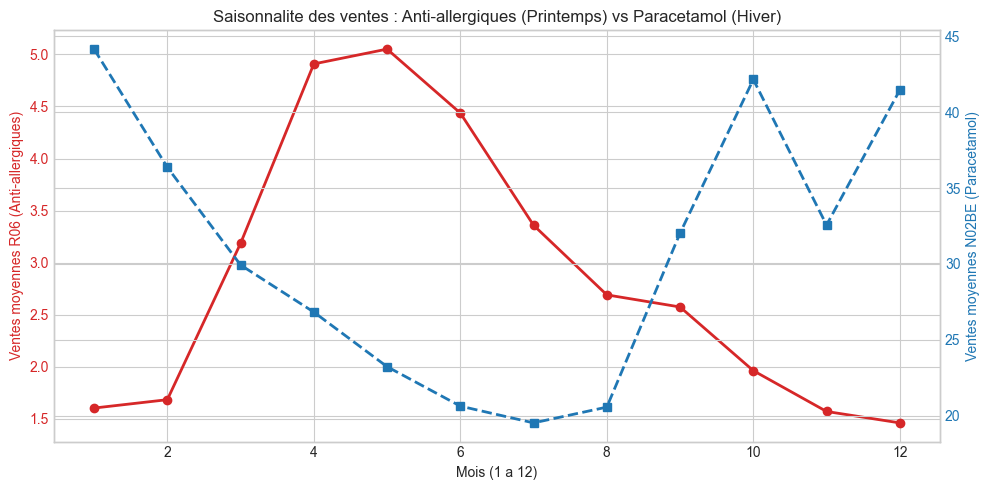

In [ ]:
# Visualisation saisonniere conservee, sans conclure sur les resultats
fig, ax1 = plt.subplots(figsize=(10, 5))

color = "tab:red"
ax1.set_xlabel("Mois (1 a 12)")
ax1.set_ylabel("Ventes moyennes R06", color=color)
ax1.plot(
    saisonnalite.index,
    saisonnalite["R06"],
    color=color,
    marker="o",
    linewidth=2,
    label="R06",
)
ax1.tick_params(axis="y", labelcolor=color)

ax2 = ax1.twinx()
color = "tab:blue"
ax2.set_ylabel("Ventes moyennes N02BE", color=color)
ax2.plot(
    saisonnalite.index,
    saisonnalite["N02BE"],
    color=color,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="N02BE",
)
ax2.tick_params(axis="y", labelcolor=color)

plt.title("Moyennes mensuelles des ventes par code ATC")
fig.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_error

# Agregation mensuelle : exclure les mois incomplets ou contenant des ventes absentes
sales_by_date = df_daily.set_index("datum_dt")[atc_cols]
df_monthly_calc = sales_by_date.resample("ME").sum(min_count=1)
observed_days = sales_by_date.resample("ME").size()
expected_days = pd.Series(
    df_monthly_calc.index.days_in_month,
    index=df_monthly_calc.index,
)
complete_calendar_month = observed_days.eq(expected_days)

for atc_code in atc_cols:
    nonmissing_sales_days = sales_by_date[atc_code].resample("ME").count()
    complete_sales_month = complete_calendar_month & nonmissing_sales_days.eq(expected_days)
    df_monthly_calc.loc[~complete_sales_month, atc_code] = np.nan

# Decoupage Train (2014-2018) / Test (2019)
train = df_monthly_calc[df_monthly_calc.index < "2019-01-01"]
test = df_monthly_calc[
    (df_monthly_calc.index >= "2019-01-01")
    & (df_monthly_calc.index < "2020-01-01")
]

if train.empty or test.empty:
    raise ValueError("Periode insuffisante pour comparer les previsions sur 2019.")

results = []
for atc_code in atc_cols:
    # Prevision naive : mois precedent (M-1)
    pred_naive = test[atc_code].shift(1)
    pred_naive.iloc[0] = train[atc_code].iloc[-1]

    # Prevision saisonniere naive : meme mois de l'annee precedente (M-12)
    pred_seasonal = df_monthly_calc[atc_code].shift(12).reindex(test.index)
    comparable = (
        test[atc_code].notna()
        & pred_naive.notna()
        & pred_seasonal.notna()
    )
    sample_count = int(comparable.sum())

    if sample_count:
        mae_naive = mean_absolute_error(
            test.loc[comparable, atc_code], pred_naive.loc[comparable]
        )
        mae_seasonal = mean_absolute_error(
            test.loc[comparable, atc_code], pred_seasonal.loc[comparable]
        )
        seasonality_predictable = "Oui" if mae_seasonal < mae_naive else "Non"
    else:
        mae_naive = np.nan
        mae_seasonal = np.nan
        seasonality_predictable = "Indéterminé"

    results.append(
        {
            "Code ATC": atc_code,
            "Mois compares": sample_count,
            "MAE Naif (M-1)": round(mae_naive, 2) if sample_count else np.nan,
            "MAE Saisonnier (M-12)": round(mae_seasonal, 2) if sample_count else np.nan,
            "Saisonnalite predictible": seasonality_predictable,
        }
    )

df_res = pd.DataFrame(results)
print("=== RESULTATS DU TEST DE PREDICTIBILITE (MOIS COMPLETS) ===")
print(df_res.to_string(index=False))

=== RESULTATS DU TEST DE PREDICTIBILITE ===
  Code ATC  MAE Naïf (M-1)  MAE Saisonnier (M-12) Saisonnalite prédictible
0    M01AB           28.93                  24.71                      Oui
1    M01AE           31.46                  27.37                      Oui
2    N02BA           16.81                  15.75                      Oui
3    N02BE          297.26                 227.92                      Oui
4     N05B           45.10                  60.10                      Non
5     N05C            6.50                   9.20                      Non
6      R03           59.90                  75.80                      Non
7      R06           40.84                  35.81                      Oui


In [ ]:
# Export des resultats, sans toucher au classeur source
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = OUTPUT_DIR / "Pharma_Analysis_Output.xlsx"
date_quality = pd.DataFrame(
    [
        {
            "Lignes journalieres": len(df_daily),
            "Dates invalides": int(invalid_date_mask.sum()),
            "Lignes concernees par une date dupliquee": int(duplicate_date_mask.sum()),
            "Debut des ventes": df_daily["datum_dt"].min(),
            "Fin des ventes": df_daily["datum_dt"].max(),
        }
    ]
)

with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    df_daily.to_excel(writer, sheet_name="Summary_Daily", index=False)
    saisonnalite.to_excel(writer, sheet_name="Monthly_Seasonality", index_label="Mois")
    calendar_comparisons.to_excel(writer, sheet_name="Calendar_Comparisons", index=False)
    quality_audit.to_excel(writer, sheet_name="Sales_Quality_Audit", index=False)
    date_quality.to_excel(writer, sheet_name="Date_Quality_Audit", index=False)
    df_res.to_excel(writer, sheet_name="Forecasting_Results", index=False)
    weather_metadata.to_excel(writer, sheet_name="Weather_Metadata", index=False)
    weather_correlations.to_excel(writer, sheet_name="Weather_Correlations", index=False)
    health_metadata.to_excel(writer, sheet_name="Health_Metadata", index=False)
    health_correlations.to_excel(writer, sheet_name="Health_Correlations", index=False)
    if "health_sales_comparison" in globals():
        health_sales_comparison.to_excel(writer, sheet_name="Health_Weekly", index=False)

print(f"Resultats exportes dans : {OUTPUT_FILE.resolve()}")
print("Le fichier source n'a pas ete modifie :", EXCEL_FILE.resolve())

 Classeur 'Pharma_Analysis_Output.xlsx' genere avec succes !


In [ ]:
# Apercu des ventes quotidiennes traitees
df_daily.head()

NameError: name 'df' is not defined